# Do feature families carry different information at different UCL lead times?

First-pass landmark logistic analysis. The refined UCL endpoint, frozen representations and chronological cohort are unchanged. The four intervals are disjoint: 1–7, 8–14, 15–30 and 31–60 days. No temporal ordering is assumed.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
while not (ROOT/'src/injury_analysis').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_temporal_common import OUT, CACHE, read_table
pd.set_option('display.max_columns',24)
def show(name,n=30): display(read_table(name).head(n))
def plot(name): display(Image(filename=str(OUT/'figures'/(name+'.png')),width=1150))


In [2]:
from src.injury_analysis.ucl_temporal_models import run_development
run_development()  # verify/reuse completed fits
show('cohort_support',n=20)
show('censoring',n=30)

Verified checkpoint: development_models


,risk_policy,partition,interval,eligible_landmarks,rows,pitchers,unknown_rows,positive_rows,prevalence,represented_events,events_with_opportunity,qualifying_events,events_without_opportunity,other_interval_ucl_rows,known_competing_rows
0,common_60d,train,1-7,123833,64646,1199,59187,119,0.001841,58,58,98,40,362,11569
1,common_60d,validation,1-7,39725,22269,750,17456,52,0.002335,25,25,34,9,137,4188
2,common_60d,test,1-7,39888,22782,729,17106,51,0.002239,28,28,43,15,149,3600
3,common_60d,train,8-14,123833,64646,1199,59187,74,0.001145,44,44,98,54,407,11569
4,common_60d,validation,8-14,39725,22269,750,17456,28,0.001257,20,20,34,14,161,4188
5,common_60d,test,8-14,39888,22782,729,17106,34,0.001492,27,27,43,16,166,3600
6,common_60d,train,15-30,123833,64646,1199,59187,145,0.002243,41,41,98,57,336,11569
7,common_60d,validation,15-30,39725,22269,750,17456,58,0.002605,17,17,34,17,131,4188
8,common_60d,test,15-30,39888,22782,729,17106,57,0.002502,21,21,43,22,143,3600
9,common_60d,train,31-60,123833,64646,1199,59187,143,0.002212,27,27,98,71,338,11569


,partition,label_status,rows
0,descriptive_2026,censored_ambiguous_or_excluded_episode,1506
1,descriptive_2026,censored_no_observed_followup,6521
2,descriptive_2026,non_ucl_competing_first_event,1760
3,descriptive_2026,observed_event_free_horizon,7861
4,descriptive_2026,ucl_first_event,129
5,test,censored_ambiguous_or_excluded_episode,2860
6,test,censored_no_observed_followup,14246
7,test,non_ucl_competing_first_event,3600
8,test,observed_event_free_horizon,18982
9,test,ucl_first_event,200


All intervals share the observed 60-day first-event cohort. This keeps the appearance population constant, at the cost of restricting follow-up. A UCL event in another interval is a zero for this specific outcome; a known intervening injury is a competing first event. Uncertain outcomes remain censored. Only 10 validation events support 31–60 days.

In [3]:
show('family_definitions',n=15)
show('omitted_groups',n=12)

,family,fields,features
0,Appearance performance,4,hbp_rate;innings_pitched;walk_rate;strikeout_rate
1,Extension,8,extension_avg;extension_sd;si_extension_avg;cu...
2,Location and strike fractions,12,zone_pct;strike_pct;first_pitch_strike_pct;loc...
3,Pitch mix and pitch-type counts,14,fastball_usage_pct;ff_pitch_count;sl_usage_pct...
4,Pitch movement,9,ivb_inches;horizontal_movement_avg;vertical_mo...
5,Pitcher background and experience,7,throws_left;age_at_appearance;days_since_mlb_d...
6,Release position and variability,19,release_x_avg;release_z_avg;release_x_sd;relea...
7,Role and recent starts,4,is_starter;starts_prev_30d;starter_share_prev_...
8,Spin,8,spin_avg;ff_spin_avg;cu_spin_avg_prev_5;si_spi...
9,Velocity,13,avg_fb_velo;fb_velo_sd;fb_velo_sd_prev_3;ff_av...


,feature,feature_group,screen_exclusion,classification_ambiguity,training_missing_fraction,support_only_sensitivity
0,arm_angle_avg,Arm angle,insufficient long-history training measurement...,NaN,0.816711,False
1,arm_angle_sd,Arm angle,insufficient long-history training measurement...,NaN,0.817549,False
2,velocity_measured_count,Measurement coverage and history support,NaN,NaN,0.000000,True
3,arm_angle_measured_count,Measurement coverage and history support,NaN,NaN,0.000000,True
4,velocity_coverage,Measurement coverage and history support,NaN,NaN,0.000000,True
5,arm_angle_coverage,Measurement coverage and history support,NaN,NaN,0.000000,True
6,first_n_fb_velo,Within-appearance velocity change,insufficient long-history training measurement...,NaN,0.800826,False
7,last_n_fb_velo,Within-appearance velocity change,insufficient long-history training measurement...,NaN,0.800826,False
8,velo_drop_game,Within-appearance velocity change,insufficient long-history training measurement...,NaN,0.800826,False
9,ff_arm_angle_avg,Arm angle,insufficient long-history training measurement...,NaN,0.848530,False


The 113-field union spans 11 usable families. Frozen Profile, Background, Departure-8, Previous-62 and Stable-62 are unchanged. Arm angle and within-outing velocity decline inherit historical-coverage exclusions; prior UCL history inherits its publication-timing exclusion. Fixed L2 logistic C=1 is used everywhere; all learned preprocessing is training-only.

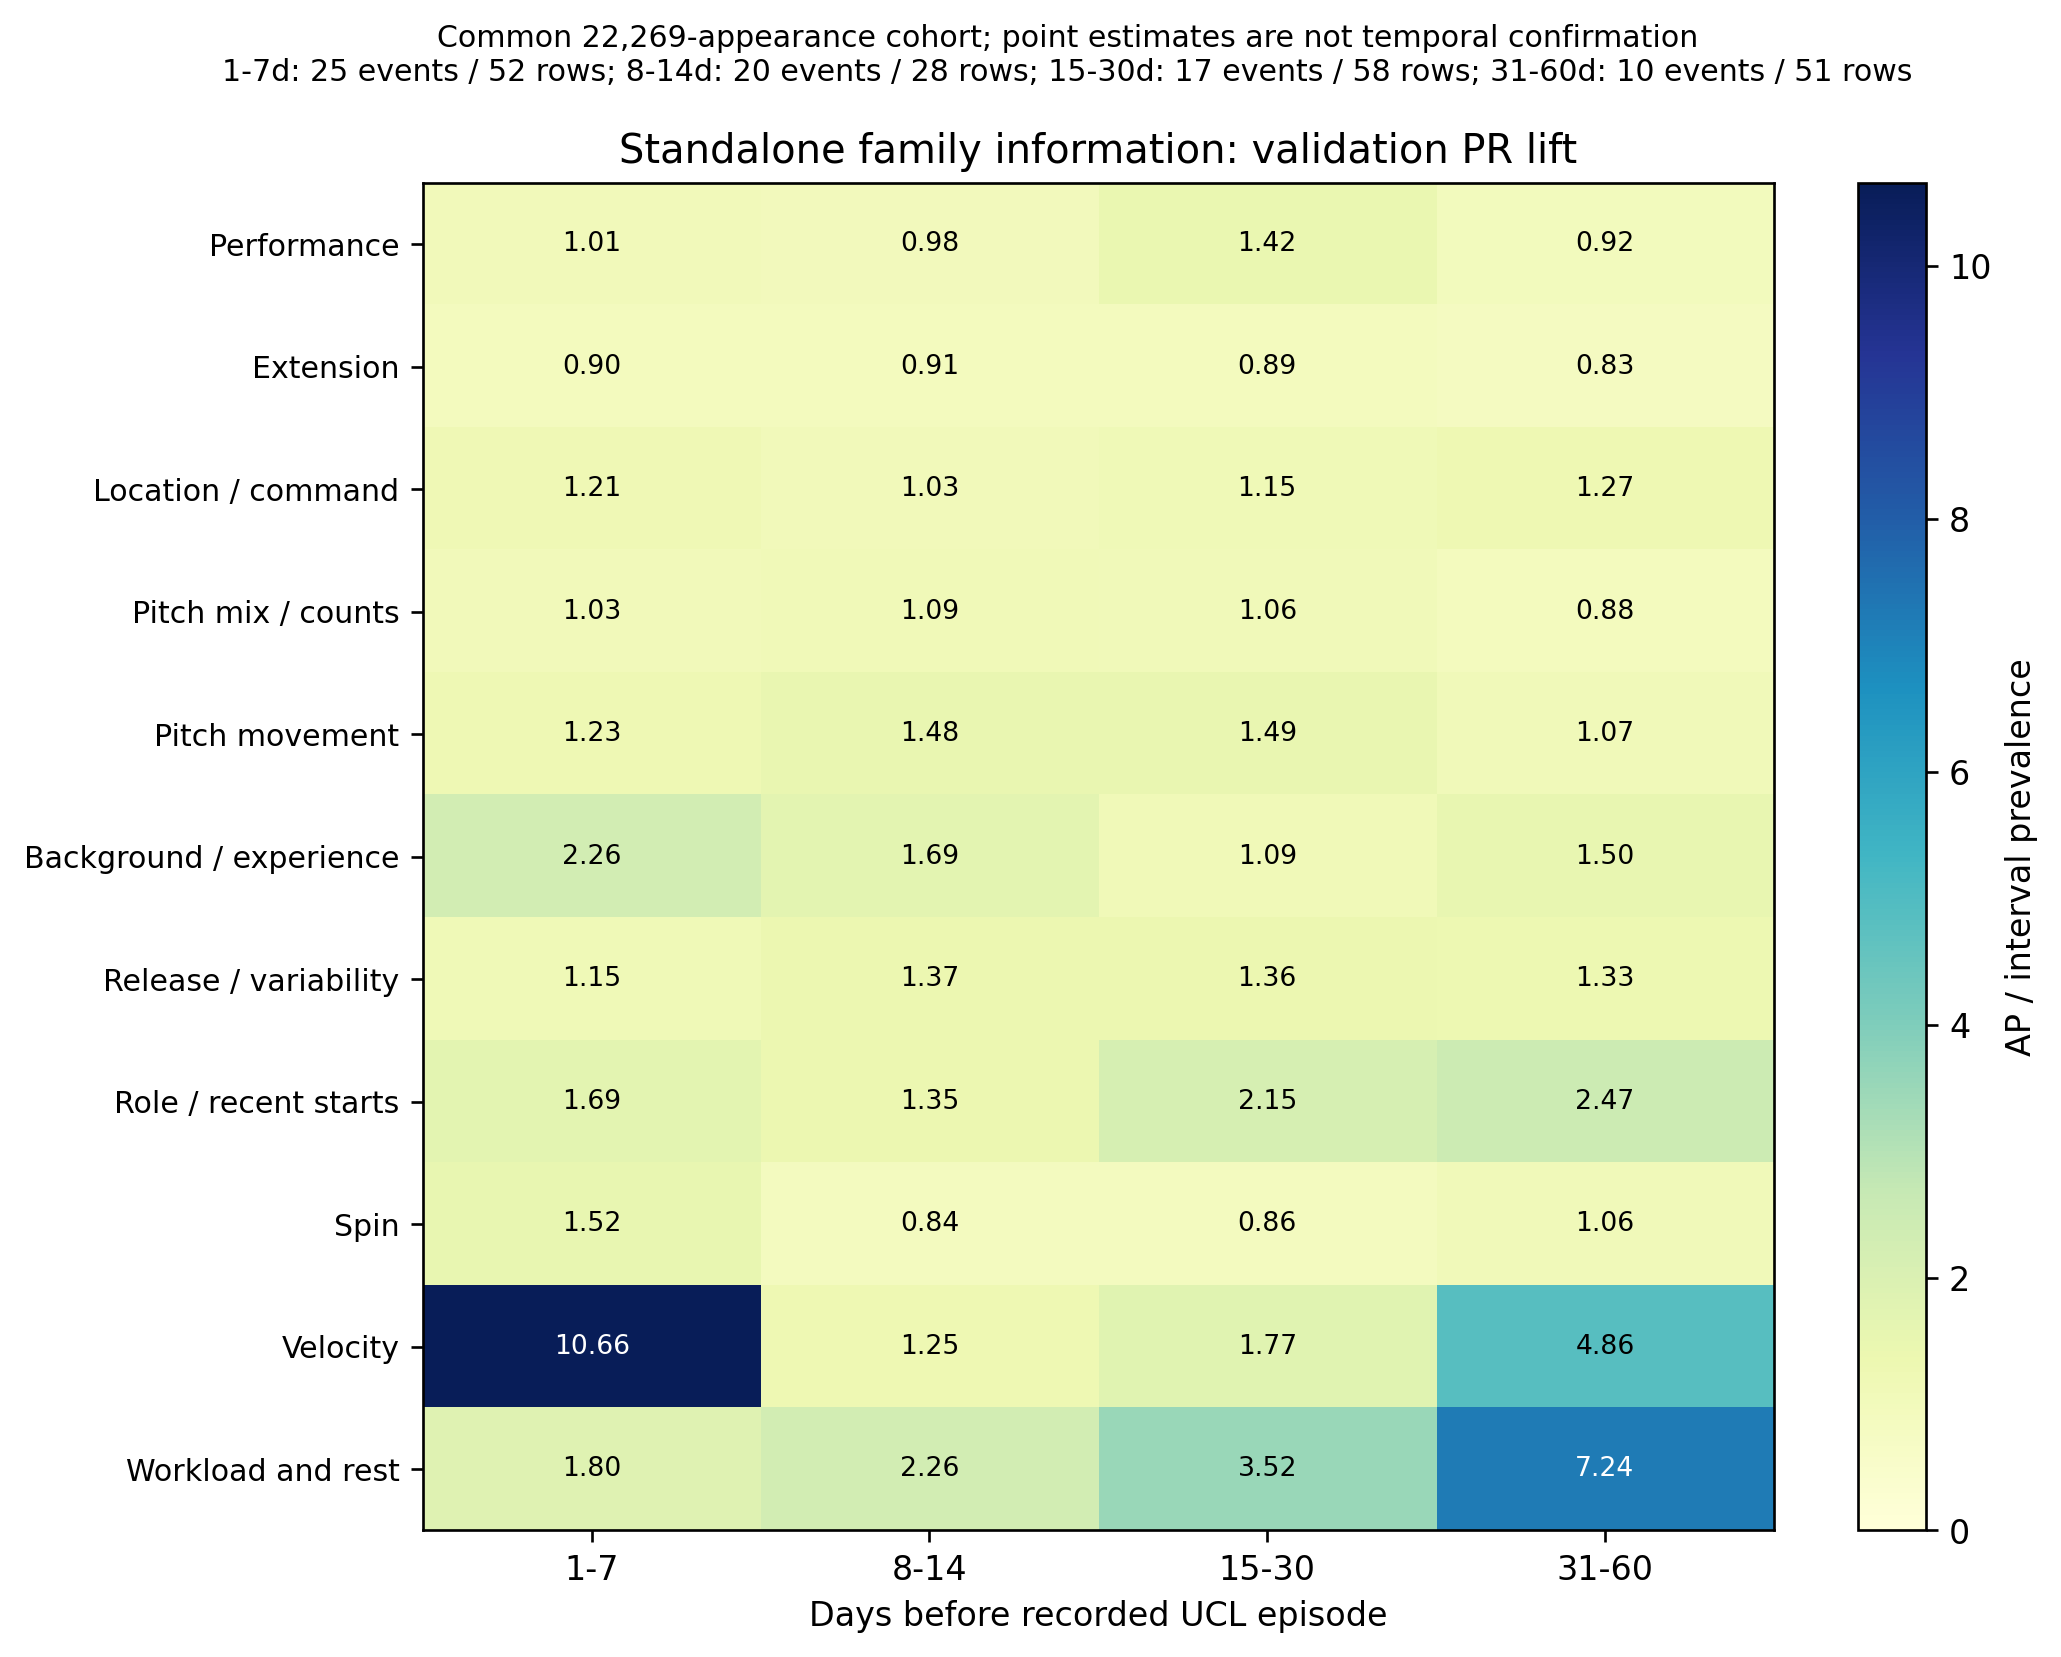

,family,interval,standalone_lift,standalone_lift_ci_low,standalone_lift_ci_high,represented_events
0,Appearance performance,1-7,1.011364,0.877607,1.319235,25
1,Extension,1-7,0.895115,0.698774,1.749514,25
2,Location and strike fractions,1-7,1.205697,0.887612,1.839554,25
3,Pitch mix and pitch-type counts,1-7,1.034033,0.850084,1.432438,25
4,Pitch movement,1-7,1.234327,0.869291,2.204530,25
5,Pitcher background and experience,1-7,2.262606,1.051037,5.344890,25
6,Release position and variability,1-7,1.152351,0.828273,2.345683,25
7,Role and recent starts,1-7,1.688831,1.165034,3.173165,25
8,Spin,1-7,1.520669,1.075599,2.598949,25
9,Velocity,1-7,10.658903,1.333445,33.738033,25


In [4]:
plot('01_family_standalone')
g=read_table('family_matrix_validation')
display(g[['family','interval','standalone_lift','standalone_lift_ci_low','standalone_lift_ci_high','represented_events']])

Large standalone PR lift is not evidence of uniquely useful information, nor proof that one family is acute or chronic. Intervals differ in width and represented events. The next comparison removes each family from a broader model.

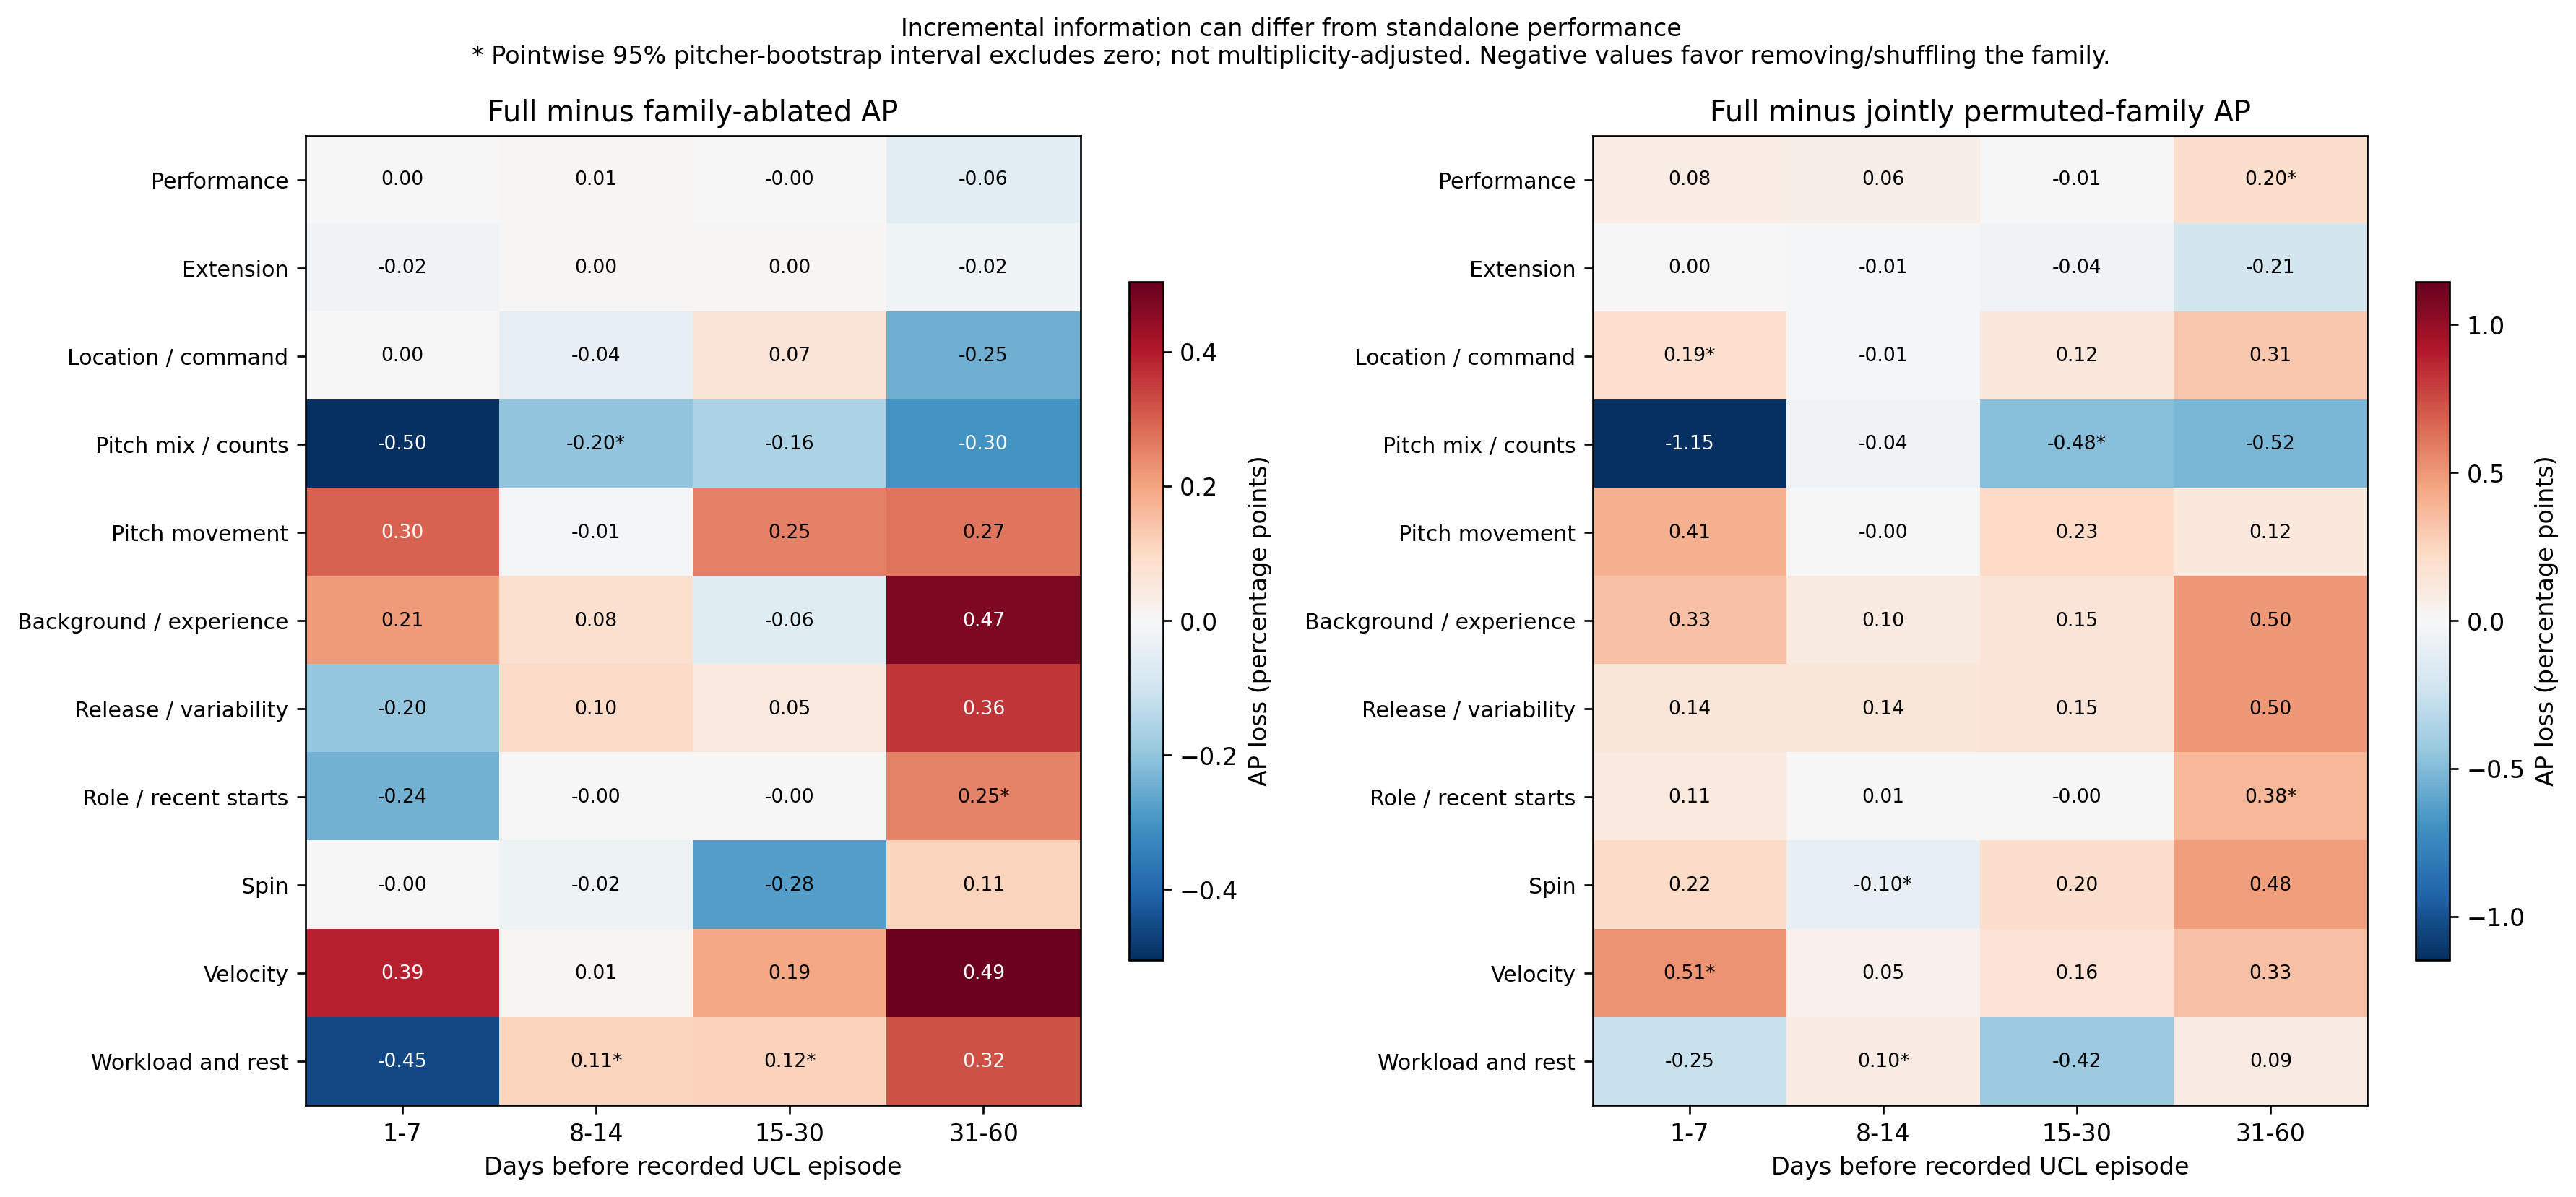

,family,interval,ablation_ap_loss,ablation_ci_low,ablation_ci_high,permutation_ap_loss,permutation_ci_low,permutation_ci_high
0,Appearance performance,1-7,0.000005,-0.001396,0.009555,0.000835,-0.000381,0.021703
1,Extension,1-7,-0.000164,-0.001912,0.018771,0.000022,-0.003148,0.013862
2,Location and strike fractions,1-7,0.000032,-0.002396,0.015159,0.001933,0.000119,0.028958
3,Pitch mix and pitch-type counts,1-7,-0.005050,-0.026391,0.000112,-0.011461,-0.037848,0.002530
4,Pitch movement,1-7,0.002997,-0.001227,0.036385,0.004062,-0.000522,0.039423
5,Pitcher background and experience,1-7,0.002132,-0.001083,0.029543,0.003333,-0.003670,0.039031
6,Release position and variability,1-7,-0.001957,-0.026512,0.003118,0.001428,-0.007989,0.035907
7,Role and recent starts,1-7,-0.002373,-0.031833,0.002197,0.001145,-0.001251,0.020686
8,Spin,1-7,-0.000034,-0.009117,0.013027,0.002177,-0.000395,0.022016
9,Velocity,1-7,0.003913,-0.000198,0.039006,0.005144,0.000315,0.040667


In [5]:
plot('02_family_incremental')
display(g[['family','interval','ablation_ap_loss','ablation_ci_low','ablation_ci_high','permutation_ap_loss','permutation_ci_low','permutation_ci_high']])

Negative ablation/permutation values are retained. Refitting after removal can improve a correlated or overfit model. Joint within-season family shuffling measures marginal reliance, not causal or fully conditional importance. Asterisks are pointwise uncertainty only.

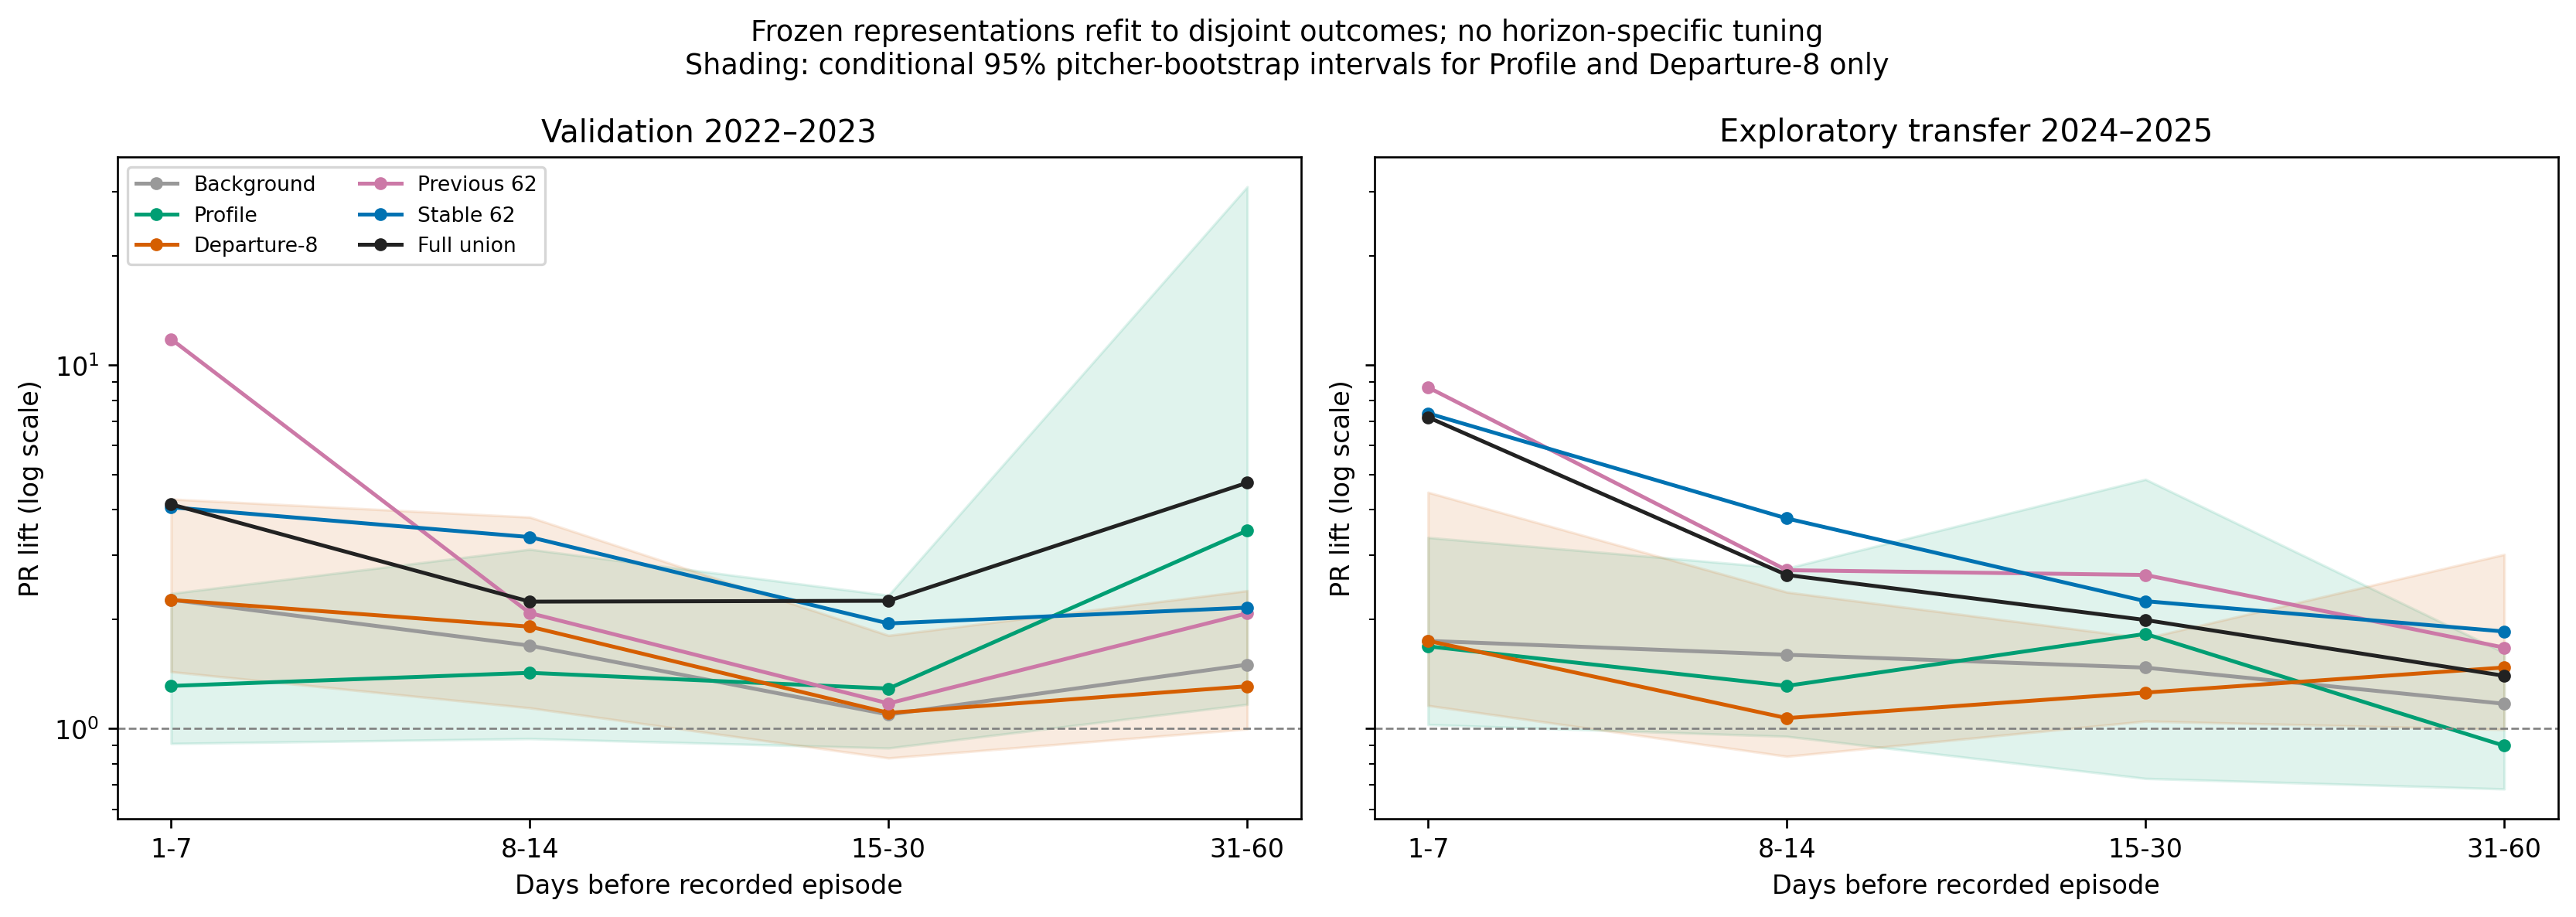

,partition,model,contrast,lift_difference,ci_low,ci_high,bootstrap_positive_fraction,valid_replicates
0,validation,Departure,1-7 minus 31-60 PR lift,0.950969,-0.522378,2.944046,0.940000,300
1,validation,Profile,1-7 minus 31-60 PR lift,-2.195802,-29.629073,0.456367,0.100000,300
2,validation,Background,1-7 minus 31-60 PR lift,0.762067,-0.714733,3.590139,0.803333,300
3,validation,Previous 62,1-7 minus 31-60 PR lift,9.709620,-0.774826,37.361919,0.900000,300
4,validation,Stable 62,1-7 minus 31-60 PR lift,1.910621,-1.187846,9.446660,0.900000,300


,partition,interval,model,fields,risk_policy,rows,pitchers,positive_rows,represented_events,prevalence,average_precision,roc_auc,...,calibration_bias,pr_lift,alerts,qualifying_events,observable_events,alerted_events,injury_event_recall,observable_event_recall,median_warning_lead_days,alerts_per_detected_event,non_actionable_alert_fraction,training_rows
0,validation,1-7,Full union,113,interval_upper_followup,35859,876,52,25,0.001450,0.006847,0.722036,...,-0.000594,4.721989,1792,34,25,7,0.205882,0.280000,1.0,256.000000,0.993862,111361
1,validation,1-7,Profile,13,interval_upper_followup,35859,876,52,25,0.001450,0.001780,0.580388,...,-0.000478,1.227371,1792,34,25,2,0.058824,0.080000,4.0,896.000000,0.998326,111361
2,validation,1-7,Departure,8,interval_upper_followup,35859,876,52,25,0.001450,0.003502,0.603956,...,-0.000372,2.414823,1792,34,25,9,0.264706,0.360000,6.0,199.111111,0.993862,111361
3,validation,8-14,Full union,113,interval_upper_followup,33495,850,28,20,0.000836,0.001863,0.627576,...,-0.000175,2.228564,1674,34,20,4,0.117647,0.200000,12.5,418.500000,0.997013,103358
4,validation,8-14,Profile,13,interval_upper_followup,33495,850,28,20,0.000836,0.001187,0.565797,...,-0.000165,1.419448,1674,34,20,1,0.029412,0.050000,12.0,1674.000000,0.998805,103358
5,validation,8-14,Departure,8,interval_upper_followup,33495,850,28,20,0.000836,0.001637,0.591623,...,-0.000087,1.958221,1674,34,20,4,0.117647,0.200000,12.0,418.500000,0.997013,103358
6,validation,15-30,Full union,113,interval_upper_followup,28875,802,58,17,0.002009,0.003854,0.640960,...,-0.000366,1.918832,1443,34,17,2,0.058824,0.117647,29.5,721.500000,0.995149,87332
7,validation,15-30,Profile,13,interval_upper_followup,28875,802,58,17,0.002009,0.002522,0.558749,...,-0.000490,1.255809,1443,34,17,1,0.029412,0.058824,29.0,1443.000000,0.997921,87332
8,validation,15-30,Departure,8,interval_upper_followup,28875,802,58,17,0.002009,0.002271,0.525563,...,-0.000318,1.130809,1443,34,17,3,0.088235,0.176471,26.0,481.000000,0.997228,87332
9,validation,31-60,Full union,113,interval_upper_followup,22269,750,51,10,0.002290,0.010870,0.694742,...,0.000574,4.746192,1113,34,10,2,0.058824,0.200000,56.5,556.500000,0.988320,64646


In [6]:
plot('03_frozen_representations')
show('reference_temporal_contrasts_validation',n=10)
show('followup_sensitivity',n=12)

Departure-8 has a larger near-versus-far point estimate, but its paired uncertainty includes zero. Profile does not establish constant susceptibility across horizons. The interval-specific follow-up sensitivity helps separate signal from the common cohort restriction. Transfer remains exploratory and did not define intervals or feature groups.